Implement a simple character-level RNN/LSTM for text generation (e.g., generating Shakespearean text)

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ==========================================
# 1. Load downloaded Shakespeare file
# ==========================================

text = open("file.txt", "r", encoding="utf-8").read()

# Use only 100000 characters for faster training
text = text[:100000]

print("Text length:", len(text))


Text length: 305


In [2]:
# ==========================================
# 2. Character encoding
# ==========================================

chars = sorted(set(text))

char_to_int = {
    c: i for i, c in enumerate(chars)
}

int_to_char = np.array(chars)

encoded = np.array([
    char_to_int[c] for c in text
])

print("Number of characters:", len(chars))

Number of characters: 34


In [3]:
# ==========================================
# 3. Create sequences
# ==========================================

seq_length = 50

X = []
y = []

for i in range(len(encoded) - seq_length):

    X.append(
        encoded[i:i + seq_length]
    )

    y.append(
        encoded[i + seq_length]
    )

X = np.array(X)
y = np.array(y)

# Use only 20000 sequences
X = X[:20000]
y = y[:20000]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (255, 50)
y shape: (255,)


In [4]:
# ==========================================
# 4. Create LSTM model
# ==========================================

model = tf.keras.Sequential([

    tf.keras.layers.Embedding(
        len(chars),
        32
    ),

    tf.keras.layers.LSTM(
        64
    ),

    tf.keras.layers.Dense(
        len(chars),
        activation="softmax"
    )
])

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ==========================================
# 6. Train
# ==========================================

history = model.fit(
    X,
    y,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 741ms/step - accuracy: 0.0262 - loss: 3.5259 - val_accuracy: 0.0769 - val_loss: 3.5206
Epoch 2/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.1397 - loss: 3.5171 - val_accuracy: 0.1154 - val_loss: 3.5132
Epoch 3/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.1528 - loss: 3.5065 - val_accuracy: 0.1154 - val_loss: 3.5036
Epoch 4/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.1572 - loss: 3.4930 - val_accuracy: 0.1154 - val_loss: 3.4897
Epoch 5/5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.1572 - loss: 3.4714 - val_accuracy: 0.1154 - val_loss: 3.4673


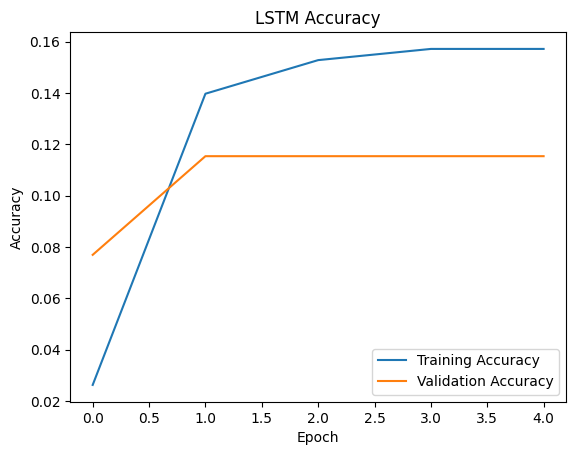

In [6]:
# ==========================================
# 7. Accuracy plot
# ==========================================

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title("LSTM Accuracy")

plt.legend()

plt.show()

In [7]:
prediction = model.predict(
    X[:100],
    verbose=0
)

predicted = np.argmax(
    prediction,
    axis=1
)

actual = y[:100]

print("\nActual characters:")
print(
    "".join(int_to_char[actual])
)

print("\nPredicted characters:")
print(
    "".join(int_to_char[predicted])
)


Actual characters:
food tasted terrible and was cold.\t0
This is the best book I have ever read.\t1
I am so disappointe

Predicted characters:
                                                                                                    


In [8]:
print("\n======================")
print("LSTM METRICS")
print("======================")

print(
    "Accuracy :",
    accuracy_score(actual, predicted)
)

print(
    "Precision:",
    precision_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)

print(
    "Recall   :",
    recall_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)

print(
    "F1 Score :",
    f1_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )
)


LSTM METRICS
Accuracy : 0.16
Precision: 0.0256
Recall   : 0.16
F1 Score : 0.044137931034482755
